# TVMaze API — Veri Toplama, Temizleme ve Keşifsel Veri Analizi

Bu notebook API üzerinden veri toplar, ham JSON verisini saklar, veri kalitesi kontrollerini yapar ve üç araştırma sorusunu analiz eder. Proje kök dizininden veya `notebooks/` klasöründen çalıştırın. İlk çalıştırmada internet bağlantısı gerekir.

In [1]:
# TVMaze API - Veri Toplama, Temizleme ve EDA
# Gerekli paketler: pip install requests pandas numpy matplotlib seaborn scipy

import json
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.ticker import MaxNLocator

## 1. PROJE DİZİNLERİ

In [2]:
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name.lower() == "notebooks" else CURRENT_DIR
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "figures"
for folder in (RAW_DIR, PROCESSED_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Proje kökü:", PROJECT_ROOT.resolve())

Proje kökü: C:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim


## 2. API'DEN VERİ TOPLAMA

In [3]:
SHOW_NAMES = [
    "The Simpsons", "Doctor Who", "Friends", "Breaking Bad",
    "Game of Thrones", "The Office", "Brooklyn Nine-Nine",
    "Grey's Anatomy", "Supernatural", "Stranger Things",
    "Black Mirror", "Sherlock"
]
BASE_URL = "https://api.tvmaze.com"
TIMEOUT = 20
DELAY = 0.35
MAX_RETRIES = 3
session = requests.Session()
session.headers.update({"User-Agent": "TVMaze-Student-EDA-Project/1.0"})


def normalize_title(value):
    return re.sub(r"[^a-z0-9]+", "", str(value).casefold())


def get_json(url, params=None):
    last_error = None
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            response = session.get(url, params=params, timeout=TIMEOUT)
            response.raise_for_status()
            return response.json()
        except requests.RequestException as exc:
            last_error = exc
            if attempt < MAX_RETRIES:
                time.sleep(attempt * 2)
    raise last_error


raw_records, collection_errors, resolved_shows = [], [], []
for requested_name in SHOW_NAMES:
    try:
        results = get_json(f"{BASE_URL}/search/shows", {"q": requested_name})
        matches = [
            item["show"] for item in results
            if normalize_title(item.get("show", {}).get("name", ""))
            == normalize_title(requested_name)
        ]
        if not matches:
            raise ValueError("TVMaze aramasında tam isim eşleşmesi bulunamadı.")

        show = matches[0]
        show_id = show["id"]
        details = get_json(f"{BASE_URL}/shows/{show_id}")
        episodes = get_json(f"{BASE_URL}/shows/{show_id}/episodes")

        # Yanlış ID veya benzer isimli farklı dizinin indirilmesini engelle.
        if details.get("id") != show_id:
            raise ValueError("Dönen dizi ID'si arama sonucuyla uyuşmuyor.")
        if normalize_title(details.get("name")) != normalize_title(requested_name):
            raise ValueError(f"Dizi adı doğrulanamadı: {details.get('name')}")

        raw_records.append({"requested_name": requested_name,
                            "show": details, "episodes": episodes})
        resolved_shows.append({"requested_name": requested_name,
                               "resolved_name": details.get("name"),
                               "show_id": show_id,
                               "episode_count": len(episodes)})
        print(f"✓ {requested_name}: {len(episodes)} bölüm (TVMaze ID: {show_id})")
    except Exception as exc:
        collection_errors.append({"requested_show": requested_name, "error": str(exc)})
        print(f"✗ {requested_name}: {exc}")
    time.sleep(DELAY)

RAW_FILE = RAW_DIR / "tvmaze_raw.json"
with RAW_FILE.open("w", encoding="utf-8") as file:
    json.dump(raw_records, file, ensure_ascii=False, indent=2)

collection_report = pd.DataFrame(resolved_shows)
errors_report = pd.DataFrame(collection_errors)
print("\nİstenen dizi:", len(SHOW_NAMES), "| Başarılı:", len(raw_records),
      "| Hatalı:", len(collection_errors))
print("Toplam çekilen bölüm:", sum(x["episode_count"] for x in resolved_shows))
if not errors_report.empty:
    print(errors_report.to_string(index=False))
    warnings.warn("Bazı diziler alınamadı; hata raporunu inceleyin.")

✓ The Simpsons: 811 bölüm (TVMaze ID: 83)


✓ Doctor Who: 700 bölüm (TVMaze ID: 766)


✓ Friends: 236 bölüm (TVMaze ID: 431)


✓ Breaking Bad: 62 bölüm (TVMaze ID: 169)


✓ Game of Thrones: 73 bölüm (TVMaze ID: 82)


✓ The Office: 202 bölüm (TVMaze ID: 526)


... (3 outputs left out)

✓ Stranger Things: 42 bölüm (TVMaze ID: 2993)


✓ Black Mirror: 32 bölüm (TVMaze ID: 305)


✓ Sherlock: 12 bölüm (TVMaze ID: 335)



İstenen dizi: 12 | Başarılı: 12 | Hatalı: 0
Toplam çekilen bölüm: 3123


## 3. JSON'U DÜZLEŞTİRME VE TEMİZLEME

In [4]:
episode_rows = []
for record in raw_records:
    show = record["show"]
    schedule_days = (show.get("schedule") or {}).get("days") or [None]
    network = (show.get("network") or {}).get("name") or \
              (show.get("webChannel") or {}).get("name")
    for ep in record["episodes"]:
        episode_rows.append({
            "show_id": show.get("id"),
            "show_name": show.get("name"),
            "show_type": show.get("type"),
            "language": show.get("language"),
            "genres": show.get("genres"),
            "network": network,
            "show_average_rating": (show.get("rating") or {}).get("average"),
            "episode_id": ep.get("id"),
            "episode_name": ep.get("name"),
            "season": ep.get("season"),
            "episode_num": ep.get("number"),
            "episode_runtime": ep.get("runtime") or ep.get("averageRuntime"),
            "episode_rating": (ep.get("rating") or {}).get("average"),
            "airdate": ep.get("airdate"),
            "air_day": schedule_days[0],
            "episode_url": ep.get("url")
        })

raw_df = pd.DataFrame(episode_rows)
if raw_df.empty:
    raise ValueError("API'den bölüm verisi alınamadı. Ham JSON ve API yanıtlarını kontrol edin.")

before_count = len(raw_df)
missing_before = raw_df.isna().sum().to_frame("missing_count")
missing_before["missing_percent"] = (missing_before["missing_count"] / before_count * 100).round(2)
duplicates_before = int(raw_df.duplicated(subset=["episode_id"]).sum())

for col in ["show_id", "episode_id", "season", "episode_num", "episode_runtime",
            "episode_rating", "show_average_rating"]:
    raw_df[col] = pd.to_numeric(raw_df[col], errors="coerce")
raw_df["airdate"] = pd.to_datetime(raw_df["airdate"], errors="coerce")
raw_df["show_name"] = raw_df["show_name"].astype("string").str.strip()
raw_df["episode_name"] = raw_df["episode_name"].astype("string").str.strip()
raw_df["primary_genre"] = raw_df["genres"].apply(
    lambda x: x[0].strip() if isinstance(x, list) and x else "Unspecified"
)
raw_df["air_day"] = raw_df["air_day"].fillna("Unknown").astype("string").str.strip()

clean_df = raw_df.drop_duplicates(subset=["episode_id"], keep="first").copy()
removed_duplicates = before_count - len(clean_df)

invalid_rating = clean_df["episode_rating"].notna() & ~clean_df["episode_rating"].between(0, 10)
invalid_rating_count = int(invalid_rating.sum())
clean_df.loc[invalid_rating, "episode_rating"] = np.nan

invalid_runtime = clean_df["episode_runtime"].notna() & (clean_df["episode_runtime"] <= 0)
invalid_runtime_count = int(invalid_runtime.sum())
clean_df.loc[invalid_runtime, "episode_runtime"] = np.nan

before_essential_filter = len(clean_df)
# Puan ve sezon ana analizlerin zorunlu alanlarıdır. Süresi olmayan kayıtlar korunur;
# yalnızca süre-puan korelasyonunda pairwise olarak dışarıda kalır.
clean_df = clean_df.dropna(subset=["episode_id", "show_name", "season", "episode_rating"]).copy()
removed_missing_essential = before_essential_filter - len(clean_df)
clean_df["primary_genre"] = clean_df["primary_genre"].replace("", "Unspecified").fillna("Unspecified")

# IQR aykırı değerlerini silme; bayrakla ve sayısını raporla.
def iqr_outlier_mask(series):
    values = series.dropna()
    result = pd.Series(False, index=series.index)
    if len(values) < 4:
        return result
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

clean_df["rating_outlier_iqr"] = iqr_outlier_mask(clean_df["episode_rating"])
clean_df["runtime_outlier_iqr"] = iqr_outlier_mask(clean_df["episode_runtime"])

clean_csv = PROCESSED_DIR / "tvmaze_episodes_clean.csv"
clean_df.to_csv(clean_csv, index=False, encoding="utf-8-sig")

cleaning_report = pd.DataFrame([
    ("rows_before_cleaning", before_count),
    ("duplicate_episode_ids_removed", removed_duplicates),
    ("invalid_rating_values_set_missing", invalid_rating_count),
    ("invalid_runtime_values_set_missing", invalid_runtime_count),
    ("rows_removed_missing_essential_fields", removed_missing_essential),
    ("rows_after_cleaning", len(clean_df)),
], columns=["check", "count"])
cleaning_report.to_csv(PROCESSED_DIR / "cleaning_report.csv", index=False)
missing_before.to_csv(PROCESSED_DIR / "missing_values_before_cleaning.csv")
missing_after = clean_df.isna().sum().to_frame("missing_count")
missing_after["missing_percent"] = (missing_after["missing_count"] / len(clean_df) * 100).round(2)
missing_after.to_csv(PROCESSED_DIR / "missing_values_after_cleaning.csv")

outlier_report = pd.DataFrame([
    {"variable": "episode_rating", "outlier_count_iqr": int(clean_df["rating_outlier_iqr"].sum()),
     "valid_count": int(clean_df["episode_rating"].notna().sum())},
    {"variable": "episode_runtime", "outlier_count_iqr": int(clean_df["runtime_outlier_iqr"].sum()),
     "valid_count": int(clean_df["episode_runtime"].notna().sum())}
])
outlier_report.to_csv(PROCESSED_DIR / "outlier_report.csv", index=False)

print("\n--- TEMİZLEME RAPORU ---")
print(cleaning_report.to_string(index=False))
print("\n--- EKSİK DEĞERLER (ÖNCE) ---")
print(missing_before.sort_values("missing_count", ascending=False).to_string())
print("\n--- EKSİK DEĞERLER (SONRA) ---")
print(missing_after.sort_values("missing_count", ascending=False).to_string())
print("\n--- IQR AYKIRI DEĞER RAPORU ---")
print(outlier_report.to_string(index=False))
print("\n--- DİZİ BAZINDA TEMİZ KAYIT SAYISI ---")
print(clean_df.groupby("show_name").size().sort_values(ascending=False).to_string())

Q1_SHOWS = ["The Simpsons", "Doctor Who", "Friends", "Grey's Anatomy", "Supernatural"]
missing_q1 = sorted(set(Q1_SHOWS) - set(clean_df["show_name"].dropna().astype(str)))
if missing_q1:
    warnings.warn(f"Araştırma 1 için veri setinde bulunmayan diziler: {missing_q1}")
else:
    print("Araştırma 1'de kullanılacak beş dizi de mevcut.")


--- TEMİZLEME RAPORU ---
                                check  count
                 rows_before_cleaning   3123
        duplicate_episode_ids_removed      0
    invalid_rating_values_set_missing      0
   invalid_runtime_values_set_missing      0
rows_removed_missing_essential_fields      4
                  rows_after_cleaning   3119

--- EKSİK DEĞERLER (ÖNCE) ---
                     missing_count  missing_percent
air_day                        732            23.44
episode_rating                   4             0.13
episode_runtime                  1             0.03
show_id                          0             0.00
genres                           0             0.00
show_name                        0             0.00
show_type                        0             0.00
language                         0             0.00
episode_id                       0             0.00
show_average_rating              0             0.00
network                          0             0.00
epis

## 4. TANIMLAYICI İSTATİSTİKLER VE YARDIMCI FONKSİYONLAR

In [5]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13,
                     "axes.titleweight": "bold", "axes.labelsize": 11})

print("\n--- TANIMLAYICI İSTATİSTİKLER ---")
print(clean_df[["season", "episode_rating", "episode_runtime"]].describe().T)
print("\n--- TÜR FREKANSLARI ---")
print(clean_df["primary_genre"].value_counts().to_string())


def bootstrap_median_ci(values, confidence=0.95, n_boot=5000, seed=42):
    values = pd.Series(values).dropna().to_numpy(dtype=float)
    if len(values) == 0:
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(n_boot, len(values)), replace=True)
    medians = np.median(samples, axis=1)
    alpha = 1 - confidence
    return (float(np.quantile(medians, alpha / 2)),
            float(np.quantile(medians, 1 - alpha / 2)))


def correlation_strength(r):
    if pd.isna(r):
        return "Hesaplanamadı"
    a = abs(r)
    strength = ("ihmal edilebilir" if a < .10 else "zayıf" if a < .30 else
                "orta" if a < .50 else "güçlü" if a < .70 else "çok güçlü")
    direction = "pozitif" if r > 0 else "negatif" if r < 0 else "yönsüz"
    return f"{strength} {direction} ilişki"


--- TANIMLAYICI İSTATİSTİKLER ---
                  count       mean        std   min   25%   50%   75%    max
season           3119.0  11.163193   8.781357   1.0   4.0   8.0  16.0   38.0
episode_rating   3119.0   8.192690   0.678893   5.3   7.7   8.2   8.7    9.8
episode_runtime  3118.0  39.059974  15.678800  25.0  30.0  30.0  60.0  142.0

--- TÜR FREKANSLARI ---
primary_genre
Comedy    1399
Drama     1020
Action     700


## 5. ARAŞTIRMA 1: SEZON İLERLEDİKÇE PUAN DÜŞÜYOR MU?

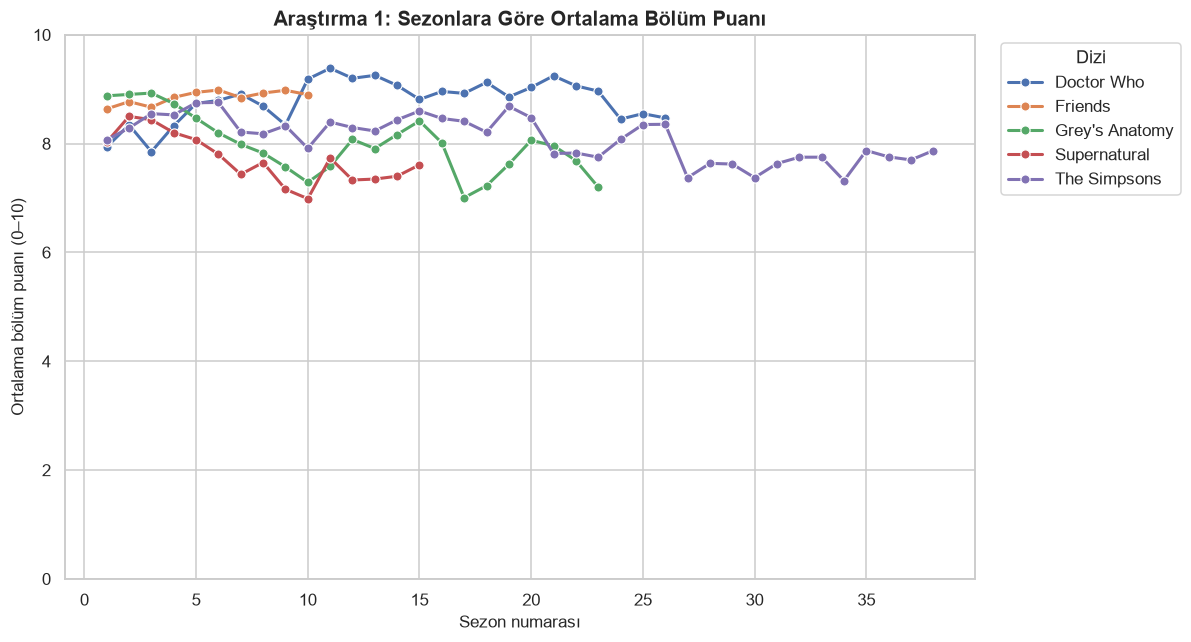


--- ARAŞTIRMA 1: SEZON EĞİLİMLERİ ---
     show_name  season_count  slope_points_per_season  spearman_rho  spearman_p_value
    Doctor Who            26                   0.0206        0.3504            0.0792
       Friends            10                   0.0313        0.6727            0.0330
Grey's Anatomy            23                  -0.0553       -0.6374            0.0011
  Supernatural            15                  -0.0763       -0.7464            0.0014
  The Simpsons            38                  -0.0255       -0.6813            0.0000
Negatif eğim düşüş, pozitif eğim yükseliş eğilimini gösterir; nedensellik kanıtı değildir.


In [6]:
q1_df = clean_df[clean_df["show_name"].isin(Q1_SHOWS)].dropna(
    subset=["show_name", "season", "episode_rating"]
).copy()
q1_df = q1_df[q1_df["season"] > 0]  # Sezon 0 özel bölümler olabilir.
season_avg = q1_df.groupby(["show_name", "season"], as_index=False).agg(
    mean_rating=("episode_rating", "mean"),
    rated_episode_count=("episode_rating", "count")
).sort_values(["show_name", "season"])

eligible = season_avg.groupby("show_name")["season"].nunique()
season_avg = season_avg[season_avg["show_name"].isin(eligible[eligible >= 2].index)]
if season_avg.empty:
    raise ValueError("Araştırma 1 için en az iki sezonu bulunan dizi verisi yok.")

fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(data=season_avg, x="season", y="mean_rating", hue="show_name",
             marker="o", linewidth=2, ax=ax)
ax.set(title="Araştırma 1: Sezonlara Göre Ortalama Bölüm Puanı",
       xlabel="Sezon numarası", ylabel="Ortalama bölüm puanı (0–10)", ylim=(0, 10))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(title="Dizi", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "q1_seasonal_fatigue_lineplot.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

trend_rows = []
for show_name, group in season_avg.groupby("show_name"):
    group = group.sort_values("season")
    x = group["season"].to_numpy(float)
    y = group["mean_rating"].to_numpy(float)
    slope = float(np.polyfit(x, y, 1)[0])
    rho, p_value = stats.spearmanr(x, y)
    trend_rows.append({"show_name": show_name, "season_count": len(group),
                       "slope_points_per_season": slope,
                       "spearman_rho": rho, "spearman_p_value": p_value})
trend_table = pd.DataFrame(trend_rows)
print("\n--- ARAŞTIRMA 1: SEZON EĞİLİMLERİ ---")
print(trend_table.round(4).to_string(index=False))
print("Negatif eğim düşüş, pozitif eğim yükseliş eğilimini gösterir; nedensellik kanıtı değildir.")

## 6. ARAŞTIRMA 2: TÜR MEDYANLARI, MEDYAN CI VE VARYANS


--- ARAŞTIRMA 2: TÜR İSTATİSTİKLERİ ---
        episode_count   mean  median  median_ci_95_low  median_ci_95_high  variance  std_dev   q1    q3
genre                                                                                                  
Comedy           1399  8.138     8.2               8.1                8.2     0.419    0.647  7.7  8.65
Drama            1020  7.903     7.9               7.8                7.9     0.377    0.614  7.5  8.30
Action            700  8.724     8.8               8.8                8.9     0.257    0.507  8.4  9.10


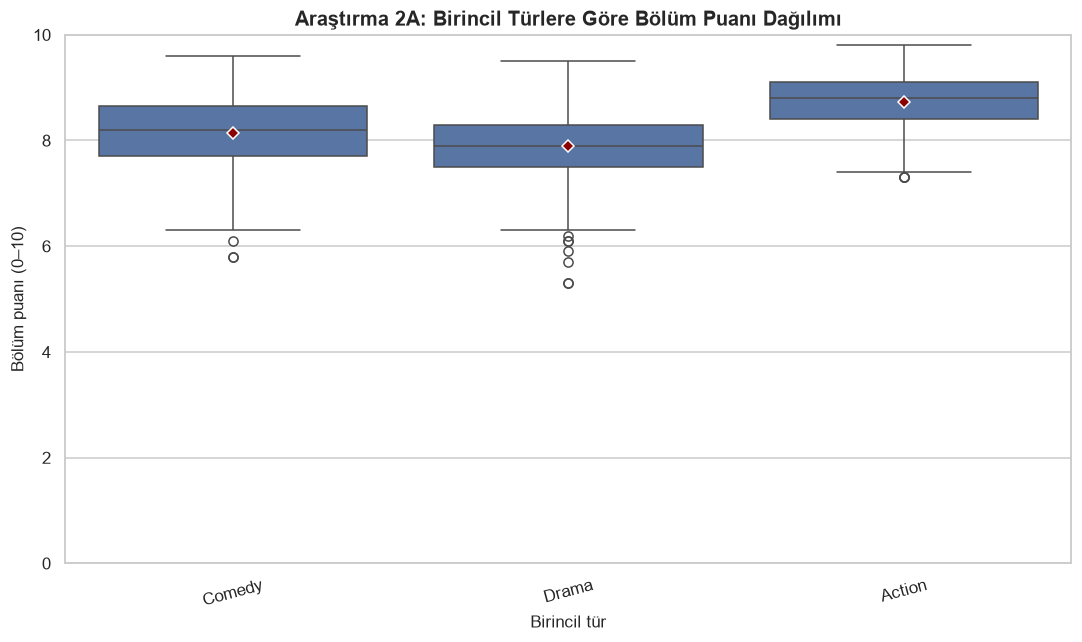

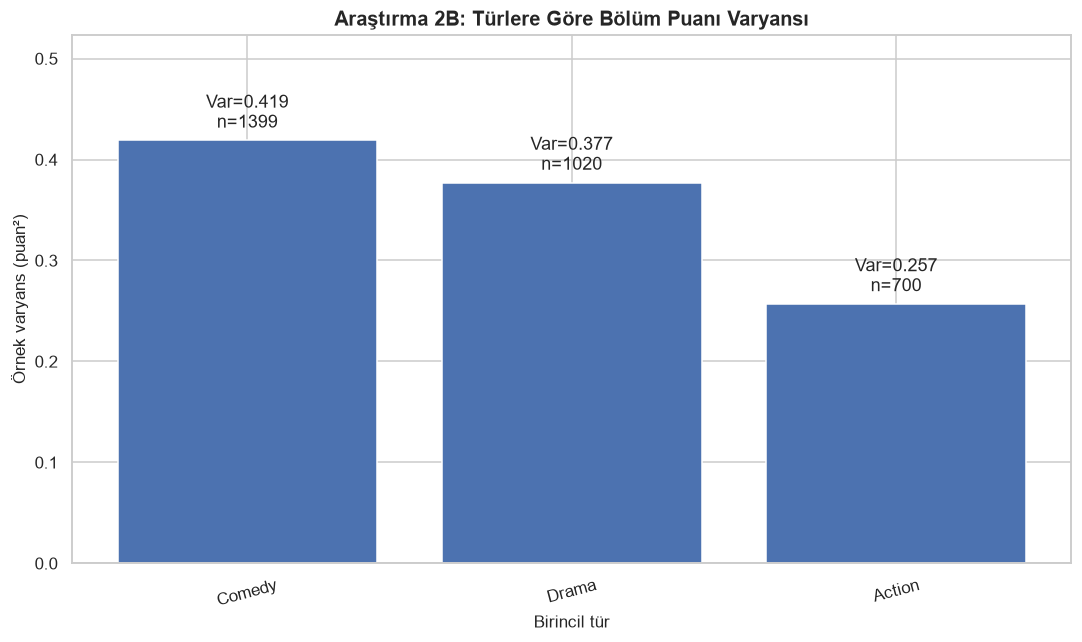

Not: Dört türden az kategori varsa yalnızca mevcut türler gösterilir. Varyans yorumunda n dikkate alınmalıdır.


In [7]:
genre_source = clean_df.dropna(subset=["primary_genre", "episode_rating"]).copy()
top_genres = genre_source["primary_genre"].value_counts().head(4).index.tolist()
if not top_genres:
    raise ValueError("Tür analizine uygun kayıt bulunamadı.")
genre_df = genre_source[genre_source["primary_genre"].isin(top_genres)].copy()
genre_rows = []
for genre in top_genres:
    values = genre_df.loc[genre_df["primary_genre"] == genre, "episode_rating"].dropna()
    ci_low, ci_high = bootstrap_median_ci(values)
    genre_rows.append({
        "genre": genre, "episode_count": len(values),
        "mean": values.mean(), "median": values.median(),
        "median_ci_95_low": ci_low, "median_ci_95_high": ci_high,
        "variance": values.var(ddof=1), "std_dev": values.std(ddof=1),
        "q1": values.quantile(.25), "q3": values.quantile(.75)
    })
genre_stats = pd.DataFrame(genre_rows).set_index("genre")
print("\n--- ARAŞTIRMA 2: TÜR İSTATİSTİKLERİ ---")
print(genre_stats.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=genre_df, x="primary_genre", y="episode_rating",
            order=top_genres, showfliers=True, showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "darkred",
                       "markeredgecolor": "white", "markersize": 6}, ax=ax)
ax.set(title="Araştırma 2A: Birincil Türlere Göre Bölüm Puanı Dağılımı",
       xlabel="Birincil tür", ylabel="Bölüm puanı (0–10)", ylim=(0, 10))
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "q2_genre_rating_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(genre_stats.index, genre_stats["variance"], edgecolor="white")
for bar, (_, row) in zip(bars, genre_stats.iterrows()):
    ax.annotate(f"Var={row['variance']:.3f}\nn={int(row['episode_count'])}",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 5), textcoords="offset points", ha="center", va="bottom")
max_var = genre_stats["variance"].max()
ax.set(title="Araştırma 2B: Türlere Göre Bölüm Puanı Varyansı",
       xlabel="Birincil tür", ylabel="Örnek varyans (puan²)")
ax.set_ylim(0, max_var * 1.25 if pd.notna(max_var) and max_var > 0 else 1)
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "q2_genre_rating_variance.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Not: Dört türden az kategori varsa yalnızca mevcut türler gösterilir. Varyans yorumunda n dikkate alınmalıdır.")

## 7. ARAŞTIRMA 3: PEARSON/SPEARMAN, P-DEĞERİ VE %95 GÜVEN ARALIĞI


--- ARAŞTIRMA 3: SÜRE- PUAN KORELASYONU ---
Eşleşmiş gözlem sayısı: 3118
  method  coefficient  p_value  ci_95_low  ci_95_high      interpretation
 Pearson     -0.32092      0.0   -0.35206    -0.28908 orta negatif ilişki
Spearman     -0.41463      0.0   -0.44445    -0.38545 orta negatif ilişki


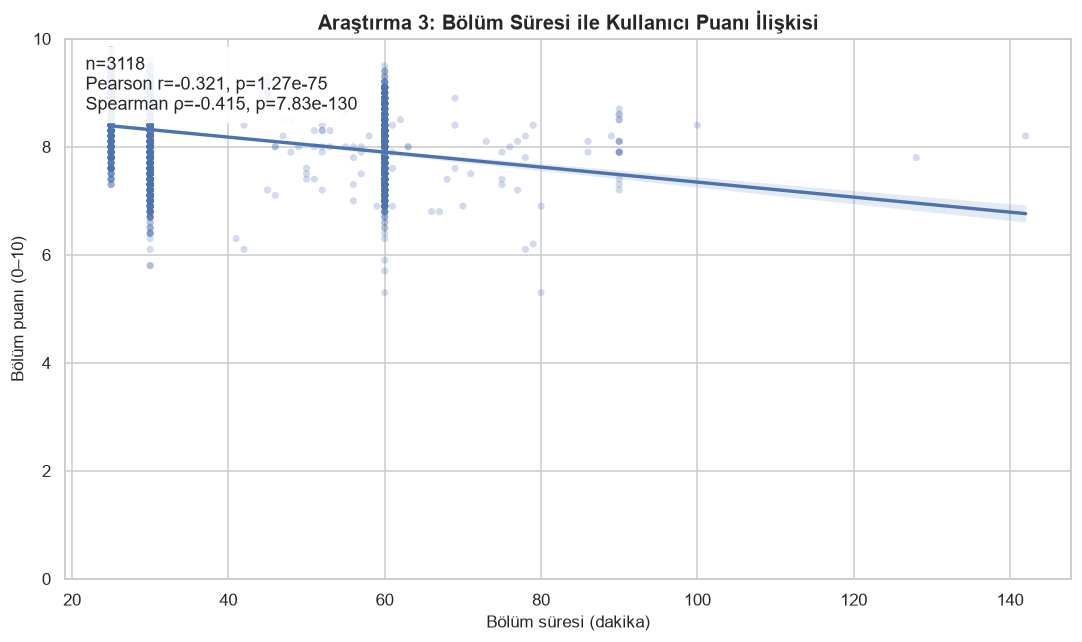

Pearson yorumu: orta negatif ilişki
Spearman yorumu: orta negatif ilişki
p < 0.05, sıfır korelasyon varsayımına karşı istatistiksel kanıt sağlar; nedensellik göstermez.


In [8]:
runtime_df = clean_df.dropna(subset=["episode_runtime", "episode_rating"]).copy()
runtime_df = runtime_df[(runtime_df["episode_runtime"] > 0) &
                        runtime_df["episode_rating"].between(0, 10)]
x = runtime_df["episode_runtime"].to_numpy(float)
y = runtime_df["episode_rating"].to_numpy(float)
n = len(x)
if n < 4:
    raise ValueError("Korelasyon analizi için yeterli gözlem yok.")

pearson_r, pearson_p = stats.pearsonr(x, y)
spearman_rho, spearman_p = stats.spearmanr(x, y)


def fisher_pearson_ci(r, n, confidence=.95):
    if n <= 3 or abs(r) >= 1:
        return np.nan, np.nan
    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)
    zcrit = stats.norm.ppf(1 - (1 - confidence) / 2)
    return float(np.tanh(z - zcrit * se)), float(np.tanh(z + zcrit * se))


def bootstrap_spearman_ci(x, y, confidence=.95, n_boot=3000, seed=42):
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        xb, yb = x[idx], y[idx]
        if np.unique(xb).size > 1 and np.unique(yb).size > 1:
            boot.append(stats.spearmanr(xb, yb).statistic)
    alpha = 1 - confidence
    return float(np.quantile(boot, alpha/2)), float(np.quantile(boot, 1-alpha/2))

pearson_ci = fisher_pearson_ci(pearson_r, n)
spearman_ci = bootstrap_spearman_ci(x, y)
correlation_results = pd.DataFrame([
    {"method": "Pearson", "coefficient": pearson_r, "p_value": pearson_p,
     "ci_95_low": pearson_ci[0], "ci_95_high": pearson_ci[1],
     "interpretation": correlation_strength(pearson_r)},
    {"method": "Spearman", "coefficient": spearman_rho, "p_value": spearman_p,
     "ci_95_low": spearman_ci[0], "ci_95_high": spearman_ci[1],
     "interpretation": correlation_strength(spearman_rho)}
])
print("\n--- ARAŞTIRMA 3: SÜRE- PUAN KORELASYONU ---")
print("Eşleşmiş gözlem sayısı:", n)
print(correlation_results.round(5).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=runtime_df, x="episode_runtime", y="episode_rating",
            scatter_kws={"alpha": .25, "s": 22, "edgecolor": "none"},
            line_kws={"linewidth": 2.2}, ax=ax)
ax.set(title="Araştırma 3: Bölüm Süresi ile Kullanıcı Puanı İlişkisi",
       xlabel="Bölüm süresi (dakika)", ylabel="Bölüm puanı (0–10)", ylim=(0, 10))
ax.text(.02, .97,
        f"n={n}\nPearson r={pearson_r:.3f}, p={pearson_p:.3g}\n"
        f"Spearman ρ={spearman_rho:.3f}, p={spearman_p:.3g}",
        transform=ax.transAxes, va="top", ha="left",
        bbox={"boxstyle": "round,pad=.4", "facecolor": "white", "alpha": .9})
fig.tight_layout()
fig.savefig(FIGURES_DIR / "q3_runtime_vs_rating_scatterplot.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Pearson yorumu:", correlation_strength(pearson_r))
print("Spearman yorumu:", correlation_strength(spearman_rho))
print("p < 0.05, sıfır korelasyon varsayımına karşı istatistiksel kanıt sağlar; nedensellik göstermez.")

## 8. SONUÇLARI DIŞARI AKTAR VE KONTROL ET

In [9]:
season_avg.to_csv(PROCESSED_DIR / "season_rating_summary.csv", index=False, encoding="utf-8-sig")
trend_table.to_csv(PROCESSED_DIR / "season_trend_results.csv", index=False, encoding="utf-8-sig")
genre_stats.to_csv(PROCESSED_DIR / "genre_statistics.csv", encoding="utf-8-sig")
correlation_results.to_csv(PROCESSED_DIR / "runtime_rating_correlations.csv", index=False, encoding="utf-8-sig")

print("\n--- ÜRETİLEN GRAFİKLER ---")
for filename in [
    "q1_seasonal_fatigue_lineplot.png",
    "q2_genre_rating_boxplot.png",
    "q2_genre_rating_variance.png",
    "q3_runtime_vs_rating_scatterplot.png"
]:
    path = FIGURES_DIR / filename
    print(("✓ " if path.exists() else "✗ ") + str(path))

print("\nNotebook/script tamamlandı. Sonuçları güncel README'ye aktarın.")


--- ÜRETİLEN GRAFİKLER ---
✓ C:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\figures\q1_seasonal_fatigue_lineplot.png
✓ C:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\figures\q2_genre_rating_boxplot.png
✓ C:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\figures\q2_genre_rating_variance.png
✓ C:\Users\HUAWEI\OneDrive\Masaüstü\API'dan veriye- Kendi Datasetim\figures\q3_runtime_vs_rating_scatterplot.png

Notebook/script tamamlandı. Sonuçları güncel README'ye aktarın.
